# Rays and waves: which way round does a plano-convex lens go?

Every optics lab has the rule: a plano-convex lens that focuses a
collimated beam should face the beam with its curved side. Mounted the other
way round, the flat side does no bending, the curved side all of it, and the
spherical aberration grows about fourfold. This notebook looks at a stock
N-BK7 plano-convex lens (f = 100 mm, R = 51.5 mm, centre thickness 3.6 mm,
1 inch diameter) that focuses a HeNe laser beam expanded to 20 mm, both ways
round. Its focus is a textbook **caustic**: the rays through the rim focus
closer to the lens than the paraxial rays, their envelope is a bright
funnel with a cusp on the axis. It is a case where ray and wave optics can
be watched side by side: the rays explain the shape, the waves show what
geometrical optics misses (fringes, the shadow side of the caustic, the
finite intensity on it). Notebook 19 compared the two orientations by
their OPD; here we look into the focus.

The conversions are in `pyoptics.raywave`:

- **rays → waves**: `rays_to_field()` turns a structured ray grid in a plane
  into a sampled field: phase k₀·OPL, amplitude from the density of the
  rays (the Jacobian of the ray map), the fields of several ray sheets
  added, with the Gouy (Maslov) phase −π/2 per caustic crossed.
  `GaussianBeamlets` gives every ray a finite width and propagates the
  beamlets in closed form, which stays finite at caustics,
- **waves → rays**: `field_to_rays()` makes a ray per sample along the local
  phase gradient (the energy flux), ready for `raytrace.System.trace()`;
  `local_spectrum_rays()` and `wigner()` use phase space distributions that
  allow several ray directions at one point.

Plan:

1. the lens both ways round: layout, aberrations, the rays at an exit plane
   5 mm behind the lens,
2. rays to waves: the field in the exit plane from the traced rays, stored
   as a `QuadraticPhaseField` (`pyoptics.analytic_phase`), so that 384²
   samples carry it to the focus,
3. the focus: ray density next to the wave intensity, and the caustic,
4. ray field summation in the caustic, where it works and where it fails,
5. Gaussian beamlets: rays with a width,
6. waves to rays: phase gradient rays, local spectra, and the Wigner
   function of the focus with the folded ray sheet,
7. which way round: the numbers.

Run time: about 2.5 minutes.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.colors import ListedColormap
from scipy.special import j1

from pyoptics.raytrace import System, Surface
from pyoptics.raywave import (rays_to_field, straight_rays, GaussianBeamlets, field_to_rays,
                              local_spectrum_rays, wigner)
from pyoptics.analytic_phase import QuadraticPhaseField, propagate
from pyoptics.utils import grid1d

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "image.origin": "lower"})
# intensity colour map on white: reversed magma, its pale low end faded to white
t = np.linspace(0, 1, 256)[:, None]
LIGHT = ListedColormap(1 - (1 - colormaps["magma_r"](t[:, 0])[:, :3])*np.clip(t/0.15, 0, 1),
                       name="light")
t_start = time.time()

um = 1e-3                  # lengths in mm
WL = 632.8e-6              # HeNe
K = 2*np.pi/WL
N_BK7 = 1.51509            # N-BK7 at 632.8 nm (Schott)
A = 10.0                   # beam radius (top hat, 20 mm diameter)
GAP = 5.0                  # exit plane behind the lens


def plano_convex(curved_first, gap=GAP):
    """f = 100 mm plano-convex N-BK7 lens behind a 20 mm stop; image plane = exit plane."""
    R, T, D = 51.5, 3.6, 12.7
    first, second = (R, np.inf) if curved_first else (np.inf, -R)
    return System([Surface(np.inf, 0.0, semi_diameter=A, label="stop"),
                   Surface(first, T, n_after=N_BK7, semi_diameter=D),
                   Surface(second, gap, n_after=1.0, semi_diameter=D)], 0, WL)


lenses = {"curved side first": plano_convex(True), "flat side first": plano_convex(False)}
for name, lens in lenses.items():
    p = lens.at_paraxial_focus()
    c = p.zernike(0.0, 16, 64)
    rim = p.trace_pupil(0.0, 0.0, 1.0)
    P, d = rim.points[-1][0], rim.directions[-1][0]
    lsa = -P[1]*d[2]/d[1]  # rim ray crosses the axis this far behind the paraxial focus
    print("{:18s} paraxial focus at z = {:.2f} mm, W040 = {:5.1f} waves, Strehl {:.3f}, "
          "rim rays cross the axis at {:+.2f} mm".format(name, p.image_z, 6*c[8],
                                                        p.strehl(0.0, 64), lsa))

curved side first  paraxial focus at z = 101.21 mm, W040 =  -4.5 waves, Strehl 0.036, rim rays cross the axis at -1.11 mm
flat side first    paraxial focus at z = 103.58 mm, W040 = -17.2 waves, Strehl 0.006, rim rays cross the axis at -4.40 mm


## 1. The lens and its rays

W040 (six times the Fringe Zernike Z9) is the spherical aberration at the
paraxial focus: −4.5 waves with the curved side towards the beam, −17 waves
the wrong way round (negative: undercorrected, the rim focuses short), a
factor of 3.8. Both lenses are far from diffraction limited at f/5. A
meridional fan of rays shows the caustic: the rim rays cross the axis
1.1 mm (curved side first) and 4.4 mm (flat side first) before the
paraxial focus. The envelope of the rays (blue) follows from the fan,
r(ρ, z) = r₀(ρ) + s(ρ)·z with the ray slope s: the rays touch it where
∂r/∂ρ = 0, i.e. at z = −r₀′/s′. It runs from the rim rays to a cusp at
the paraxial focus.

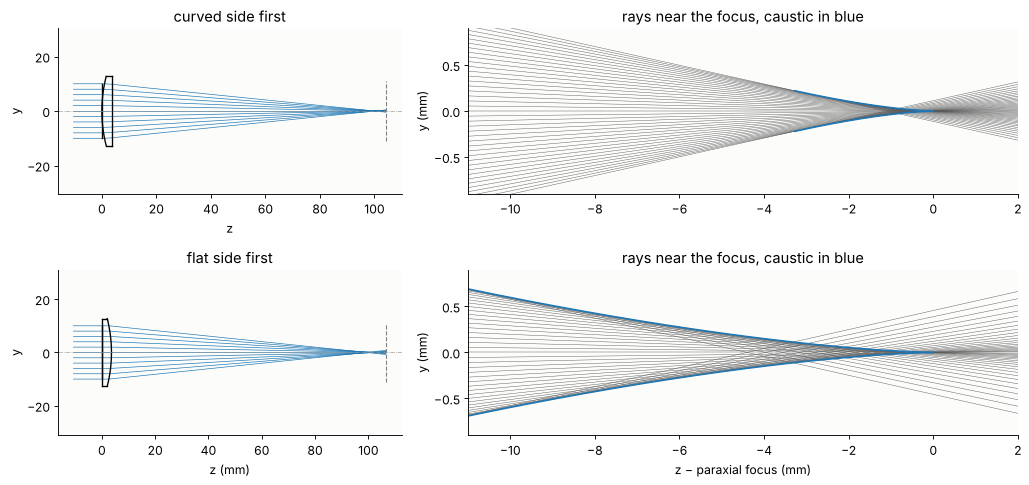

In [2]:
def meridional_fan(lens, n=20001):
    """Heights r0 and slopes s = dr/dz of a fan in the exit plane, pupil coordinates rho."""
    rho = np.linspace(-1, 1, n)
    b = lens.trace_pupil(0.0, 0*rho, rho)
    P, d = b.points[-1], b.directions[-1]
    return rho, P[:, 1], d[:, 1]/d[:, 2], P[0, 2]


def caustic(rho, r0, s):
    """Envelope of the fan: z (relative to the exit plane) and r, for rho > 0."""
    dr, ds = np.gradient(r0, rho), np.gradient(s, rho)
    zc = -dr/ds
    ok = rho > 0.02
    return zc[ok], (r0 + s*zc)[ok]


fans = {name: meridional_fan(lens) for name, lens in lenses.items()}
foci = {name: lens.at_paraxial_focus().image_z for name, lens in lenses.items()}

fig, axes = plt.subplots(2, 2, figsize=(13, 6.2), gridspec_kw={"width_ratios": [1, 1.6]})
for row, (name, lens) in zip(axes, lenses.items()):
    lens.with_image_distance(foci[name] - lens.vertex_z[-1] + 3).draw(ax=row[0], fields=[0.0],
                                                                      n_rays=11, lw=0.6)
    row[0].set_title(name)
    rho, r0, s, ze = fans[name]
    zz = np.linspace(foci[name] - 11, foci[name] + 2, 2)
    for i in range(0, len(rho), 500):
        row[1].plot(zz - foci[name], r0[i] + s[i]*(zz - ze), color="0.35", lw=0.4)
    zc, rc = caustic(rho, r0, s)
    for sign in (1, -1):
        row[1].plot(zc + ze - foci[name], sign*rc, color="C0", lw=1.5)
    row[1].set_xlim(-11, 2), row[1].set_ylim(-0.9, 0.9)
    row[1].set_ylabel("y (mm)")
    row[1].set_title("rays near the focus, caustic in blue")
axes[1, 1].set_xlabel("z − paraxial focus (mm)")
axes[1, 0].set_xlabel("z (mm)")
plt.tight_layout()

## 2. Rays to waves in the exit plane

`rays_to_field()` needs rays on a structured grid, so that neighbouring rays
span tubes (triangles). A polar grid of 120 × 240 pupil points fits the
round aperture exactly (the last azimuth is a copy of the first, so the grid
closes without a seam). Each tube keeps the power it had in the stop, its
irradiance in the exit plane is the stop irradiance (1) times the area
ratio; the phase inside the tube is interpolated from the optical paths and
directions of its three rays.

5 mm behind the lens the field is still a single sheet, but its wavefront
converges with R ≈ 92 mm: sampling the complete field over 20 mm would need
L²/(λR) ≈ 7000 samples per axis. The ray field is evaluated pointwise,
so the sphere can be divided out exactly: the remainder (the aberration)
is smooth and 384² samples hold it. It is stored as a `QuadraticPhaseField`
with the analytic sphere, whose radius is fitted to the ray slopes.

In [3]:
def polar_rays(lens, n_r=120, n_phi=240):
    rho, phi = np.linspace(0, 1, n_r), np.linspace(0, 2*np.pi, n_phi + 1)
    R, PHI = np.meshgrid(rho, phi)
    px, py = R*np.cos(PHI), R*np.sin(PHI)
    px[-1], py[-1] = px[0], py[0]  # close the grid exactly
    b = lens.trace_pupil(0.0, px.ravel(), py.ravel())
    shape = px.shape
    return (b.points[-1].reshape(shape + (3,)), b.directions[-1].reshape(shape + (3,)),
            b.opl[-1].reshape(shape), np.stack([A*px, A*py], -1))


def fitted_radius(P, D):
    r = np.hypot(P[..., 0], P[..., 1])
    slope = (P[..., 0]*D[..., 0] + P[..., 1]*D[..., 1])/np.maximum(r, 1e-12)/D[..., 2]
    return -np.sum(r**2)/np.sum(r*slope)


x_e = grid1d(-10.2, 10.2, 384)
rays, exit_fields = {}, {}
for name, lens in lenses.items():
    P, D, S, launch = rays[name] = polar_rays(lens)
    t0 = time.perf_counter()
    u = rays_to_field(x_e, x_e, P, D, S, WL, launch=launch)
    dt = time.perf_counter() - t0
    R = fitted_radius(P, D)
    exit_fields[name] = QuadraticPhaseField.from_field(u, x_e, x_e, WL, R=-R)
    power = np.sum(np.abs(u)**2)*(x_e[1] - x_e[0])**2
    print("{:18s} {:.2f} s, power {:.2f} mm² (stop: {:.2f}), sphere R = {:.2f} mm".format(
        name, dt, power, np.pi*A**2, R))

curved side first  0.22 s, power 314.14 mm² (stop: 314.16), sphere R = 91.94 mm


flat side first    0.14 s, power 314.08 mm² (stop: 314.16), sphere R = 92.33 mm


The power of the ray field (|u|² integrated over the plane) is that of the
stop to 0.03 %. The amplitude grows slightly towards the rim (the rim rays
converge faster, the rays crowd), the residual phase over the fitted sphere
is the spherical aberration, balanced by the focus of the sphere: 7 waves
peak to valley the wrong way round. Its step between samples stays well
below π, so the 384² samples are enough.

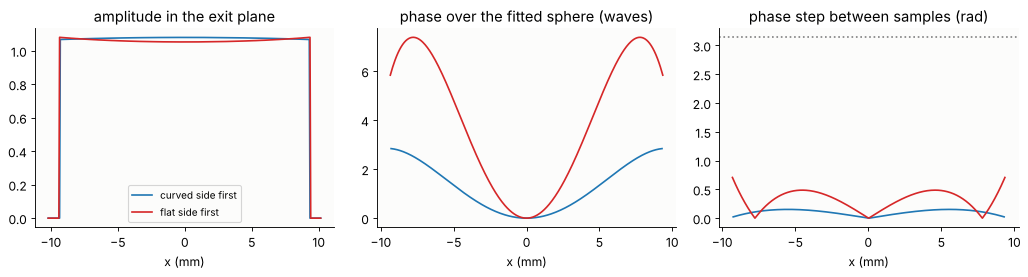

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
c = len(x_e)//2
for name, ls in zip(lenses, ("C0", "C3")):
    f = exit_fields[name]
    amp = np.abs(f.amplitude[c])
    res = np.unwrap(np.angle(f.amplitude[c]))
    inside = amp > 0
    res = res - res[c]
    axes[0].plot(x_e, amp, ls, label=name)
    axes[1].plot(x_e[inside], res[inside]/(2*np.pi), ls, label=name)
    steps = np.abs(np.angle(f.amplitude[c, 1:]*np.conj(f.amplitude[c, :-1])))[inside[1:] & inside[:-1]]
    axes[2].plot(x_e[1:][inside[1:] & inside[:-1]], steps, ls, label=name)
axes[0].set_title("amplitude in the exit plane"), axes[0].set_xlabel("x (mm)")
axes[1].set_title("phase over the fitted sphere (waves)"), axes[1].set_xlabel("x (mm)")
axes[2].set_title("phase step between samples (rad)"), axes[2].set_xlabel("x (mm)")
axes[2].axhline(np.pi, color="0.5", ls=":")
axes[0].legend(fontsize=9)
plt.tight_layout()

## 3. The focus: rays and waves

**Waves**: `analytic_phase.propagate()` carries the exit field to planes
around the focus (angular spectrum, non-paraxial; the sphere stays
analytic), each evaluated on a line through the axis (the beam is round)
with 1.5 µm sampling, ten times finer than the Airy radius.

**Rays**: the geometrical irradiance from the density of a dense meridional
fan. With rotational symmetry a ray at pupil height ρ stands for a ring of
power 2πρ dρ; in the plane z it lands at the height r(ρ, z), and the rings
that land in the annulus around r give the irradiance there. The ray
picture is singular on the caustic (blue, from section 1) and on the axis.

Both on a logarithmic scale over 40 dB, relative to the peak of the wave
intensity.

through focus: 65.4 s


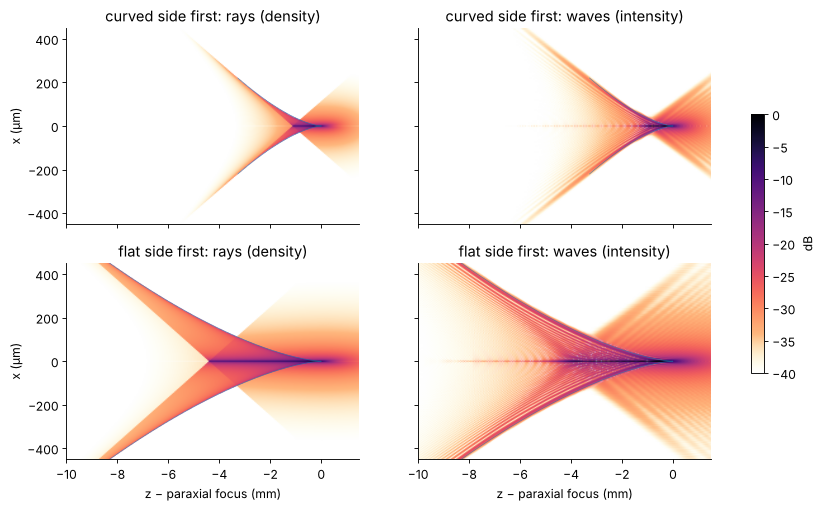

In [5]:
zs = np.linspace(-10, 1.5, 231)        # relative to the paraxial focus
x_f = grid1d(-0.6, 0.6, 800)
y_line = np.array([0.0, x_f[1] - x_f[0]])


def wave_section(name, zs, x=x_f):
    f, ze = exit_fields[name], lenses[name].image_z
    rows = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        for z in zs:
            rows.append(propagate(f, foci[name] + z - ze, x_out=x, y_out=y_line).field()[0])
    return np.array(rows)


def ray_section(name, zs, x=x_f, n=400001):
    rho, r0, s, ze = meridional_fan(lenses[name], n)
    ring = np.pi*A**2*np.abs(rho)*(rho[1] - rho[0])  # half the ring for each sign of rho
    edges = np.concatenate([x - 0.5*(x[1] - x[0]), [x[-1] + 0.5*(x[1] - x[0])]])
    rows = []
    for z in zs:
        r = r0 + s*(foci[name] + z - ze)
        # rays at r reach the point -r too: mirror the fan
        H = np.histogram(np.r_[r, -r], edges, weights=np.r_[ring, ring]/2)[0]
        rows.append(H/(np.pi*np.maximum(np.abs(x), 0.5*(x[1] - x[0]))*2*(x[1] - x[0])))
    return np.array(rows)


def show(ax, I, zs, x=x_f, ref=None, dB=40):
    ref = I.max() if ref is None else ref
    return ax.imshow(10*np.log10(I.T/ref + 1e-12), extent=[zs[0], zs[-1], x[0]/um, x[-1]/um],
                     aspect="auto", cmap=LIGHT, vmin=-dB, vmax=0, interpolation="bilinear")


t0 = time.perf_counter()
waves = {name: wave_section(name, zs) for name in lenses}
geo = {name: ray_section(name, zs) for name in lenses}
print("through focus: {:.1f} s".format(time.perf_counter() - t0))

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=True)
for row, name in zip(axes, lenses):
    I = np.abs(waves[name])**2
    show(row[0], geo[name], zs, ref=I.max())
    im = show(row[1], I, zs)
    rho, r0, s, ze = fans[name]
    zc, rc = caustic(rho, r0, s)
    for ax in row:
        for sign in (1, -1):
            ax.plot(zc + ze - foci[name], sign*rc/um, color="C0", lw=0.6, alpha=0.7)
    row[0].set_title(name + ": rays (density)")
    row[1].set_title(name + ": waves (intensity)")
    row[0].set_ylabel("x (µm)")
axes[0, 0].set_ylim(-450, 450), axes[0, 0].set_xlim(zs[0], zs[-1])
for ax in axes[1]:
    ax.set_xlabel("z − paraxial focus (mm)")
fig.colorbar(im, ax=axes, shrink=0.6, label="dB")

The rays get the overall picture right: the bright funnel of the caustic,
its cusp at the paraxial focus, the rim rays crossing the axis in the
marginal focus. The waves add the rest:

- **fringes** inside the caustic, where every point is reached by several
  rays (three in the meridional plane) that interfere,
- a **shadow** outside it: the wave intensity decays smoothly (an Airy
  function tail), the ray density drops to zero,
- the bright **axial line** of the rays (every ray crosses the axis, the
  axis is a caustic too) is a thin, finite spike of the wave intensity:
  its width is the diffraction limit λ/(2 NA),
- a faint axial line **in front of** the marginal focus, where no ray
  reaches the axis: the diffracted wave of the hard edge of the stop, whose
  ring converges on the axis (the boundary diffraction wave of Young and
  Rubinowicz, the edge rays of Keller's geometrical theory of diffraction).

Wrong way round the funnel is four times as long (LSA ∝ W040), the
intensity is spread over a larger volume.

## 4. Ray field summation in the caustic

`rays_to_field()` works in any plane, not only in front of the caustic: it
adds the fields of all ray tubes that cover a sample, with their phases and
the Gouy phase of the caustics they crossed. This is the asymptotic
(geometrical optics) field. Below, the profiles in three planes of the
flat-first lens: in front of the marginal focus (z = −9.5 mm, one sheet of
rays everywhere but close to the axis), near the circle of least confusion
(−6 mm) and at the paraxial focus (0 mm), compared with the wave.

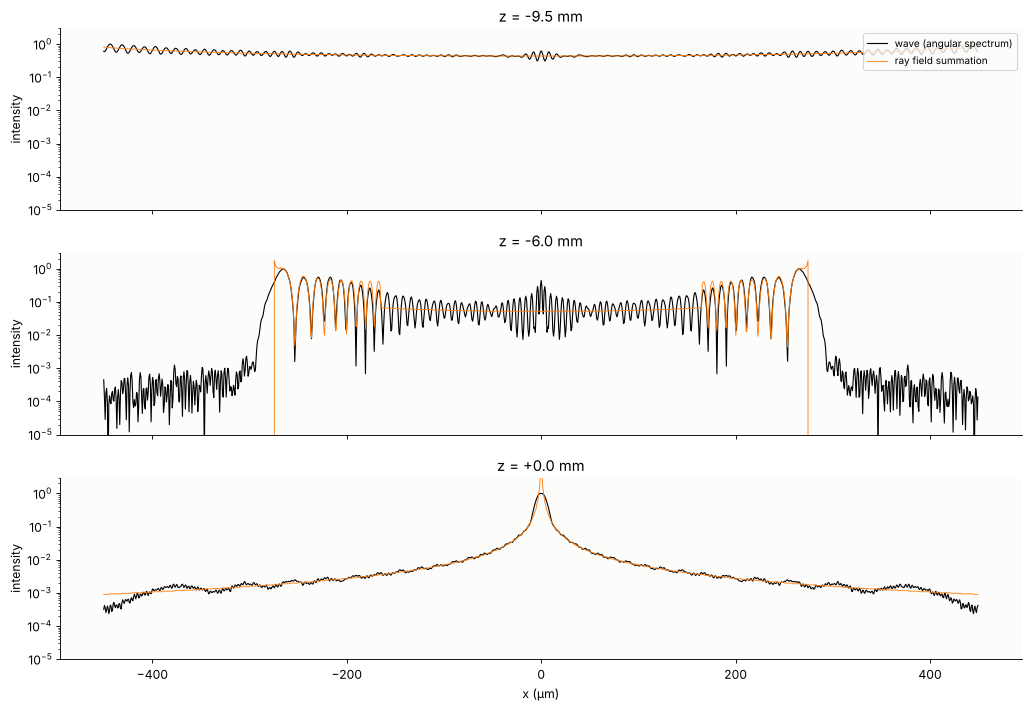

In [6]:
name = "flat side first"
P, D, S, launch = rays[name]
planes = (-9.5, -6.0, 0.0)
x_p = grid1d(-0.45, 0.45, 1200)
y_p = np.array([0.0, x_p[1] - x_p[0]])
fig, axes = plt.subplots(len(planes), 1, figsize=(13, 9), sharex=True)
for ax, z in zip(axes, planes):
    Pz, Sz = straight_rays(P, D, S, foci[name] + z)
    u_rays = rays_to_field(x_p, y_p, Pz, D, Sz, WL, launch=launch)[0]
    u_wave = wave_section(name, [z], x_p)[0]
    I0 = np.max(np.abs(u_wave)**2)
    ax.semilogy(x_p/um, np.abs(u_wave)**2/I0, color="k", lw=1.0, label="wave (angular spectrum)")
    ax.semilogy(x_p/um, np.abs(u_rays)**2/I0, color="C1", lw=0.8, label="ray field summation")
    ax.set_ylim(1e-5, 3)
    ax.set_title("z = {:+.1f} mm".format(z))
    ax.set_ylabel("intensity")
axes[0].legend(loc="upper right", fontsize=9)
axes[-1].set_xlabel("x (µm)")
plt.tight_layout()

Inside the caustic, the ray field summation reproduces the wave fringes in
position and contrast: that is interference of ray sheets with the correct
optical paths and Gouy phases. It fails where geometrical optics must fail:

- on the caustics (the ring of the funnel, and the axis) the ray tubes
  collapse, the area ratio diverges, and the summed intensity spikes,
- in the shadow outside the caustic there are no rays, so the ray field is
  exactly zero, while the wave decays smoothly.

The width of the failing zone around a caustic is the scale of the Airy
function, (λ²/κ)^{1/3} for a caustic of curvature κ: a few µm here, which
is why the rays are so good everywhere else.

The rest of the difference, the fast ripple of the wave at −9.5 mm and the
fine fringes at the centre at −6 mm, is not a failure of the summation: it
is the edge diffracted wave of the hard stop (section 3), which the rays
from inside the aperture do not contain. With a soft edge (the irradiance
in the stop falls to zero over the outer 5 % of the radius, a cos² taper,
passed to `rays_to_field()` as `irradiance`) it disappears from the wave,
and the median deviation of the ray field from the wave drops by a factor
of 2 to 10. In
the table, the deviations are relative to the peak amplitude of the wave in
the plane.

In [7]:
def taper(rho, width=0.05):
    # irradiance 1 inside, cos² roll-off to 0 over the outer width of the stop
    return np.cos(0.5*np.pi*np.clip((rho - 1 + width)/width, 0, 1))**2


irr_soft = taper(np.hypot(launch[..., 0], launch[..., 1])/A)
u_soft = rays_to_field(x_e, x_e, P, D, S, WL, launch=launch, irradiance=irr_soft)
exit_soft = QuadraticPhaseField.from_field(u_soft, x_e, x_e, WL, R=-fitted_radius(P, D))


def wave_line(field, z, x):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return propagate(field, foci[name] + z - lenses[name].image_z, x_out=x,
                         y_out=np.array([0.0, x[1] - x[0]])).field()[0]


def ray_line(z, x, irradiance):
    Pz, Sz = straight_rays(P, D, S, foci[name] + z)
    return rays_to_field(x, np.array([0.0, x[1] - x[0]]), Pz, D, Sz, WL, launch=launch,
                         irradiance=irradiance)[0]


print("ray field summation vs. wave, deviation relative to the peak:")
print("{:>8s} {:>14s} {:>14s}".format("z (mm)", "hard edge", "soft edge"))
for z in planes:
    devs = []
    for field, irr in ((exit_fields[name], 1.0), (exit_soft, irr_soft)):
        u_w, u_r = wave_line(field, z, x_p), ray_line(z, x_p, irr)
        devs.append(np.median(np.abs(u_r - u_w))/np.max(np.abs(u_w)))
    print("{:8.1f} {:13.1%}  {:13.1%}".format(z, *devs))

ray field summation vs. wave, deviation relative to the peak:
  z (mm)      hard edge      soft edge


    -9.5          5.1%           0.5%


    -6.0          5.8%           2.5%


     0.0          0.5%           0.1%


## 5. Gaussian beamlets: rays with a width

The cure for the caustic is to give every ray a width. `GaussianBeamlets`
writes the exit field as a sum of Gaussian beamlets centred on the rays,
each with the local tilt and curvature of the wavefront (the curvature
follows from the directions of the neighbouring rays), and propagates each
beamlet in closed form along its ray: its complex q parameter evolves, its
Gouy phase builds up smoothly, and it never becomes singular. Here one beamlet per
ray of a 101 × 101 Cartesian pupil grid (7 800 beamlets, spacing 0.2 mm,
radius 0.3 mm), with the hard edge of the stop.

GaussianBeamlets(7837 beamlets, wavelength=0.0006328, n=1.0, z0=8.6)


beamlet sum on 34650 points: 31.2 s


Gaussian beamlets vs. wave, deviation relative to the peak (median, maximum):


z =  -9.5 mm: hard edge  5.0%, 14.4%   soft edge  0.5%,  6.1%


z =  -6.0 mm: hard edge  3.1%, 84.8%   soft edge  1.3%, 14.0%


z =  +0.0 mm: hard edge  0.4%,  5.6%   soft edge  0.1%,  0.5%


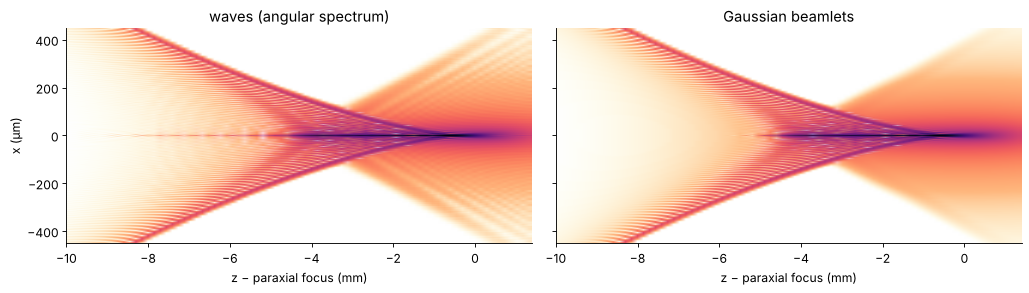

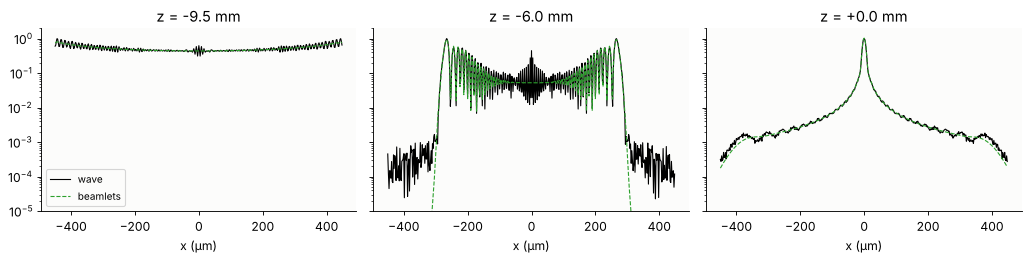

In [8]:
p = np.linspace(-1, 1, 101)
PX, PY = np.meshgrid(p, p)
inside = PX**2 + PY**2 <= 1
b = lenses[name].trace_pupil(0.0, PX[inside], PY[inside])
Pg = np.full(PX.shape + (3,), np.nan)
Dg = np.full(PX.shape + (3,), np.nan)
Sg = np.full(PX.shape, np.nan)
Pg[inside], Dg[inside], Sg[inside] = b.points[-1], b.directions[-1], b.opl[-1]
beamlets = GaussianBeamlets.from_rays(Pg, Dg, Sg, WL, launch=np.stack([A*PX, A*PY], -1))
print(beamlets)

t0 = time.perf_counter()
x_b = grid1d(-0.45, 0.45, 450)
zs_b = zs[::3]
beam_rows = np.array([beamlets.field(x_b, 0*x_b, foci[name] + z) for z in zs_b])
print("beamlet sum on {} points: {:.1f} s".format(beam_rows.size, time.perf_counter() - t0))
wave_b = wave_section(name, zs_b, x_b)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
I_w = np.abs(wave_b)**2
show(axes[0], I_w, zs_b, x_b)
show(axes[1], np.abs(beam_rows)**2, zs_b, x_b, ref=I_w.max())
axes[0].set_title("waves (angular spectrum)")
axes[1].set_title("Gaussian beamlets")
axes[0].set_ylabel("x (µm)")
for ax in axes:
    ax.set_xlabel("z − paraxial focus (mm)")
plt.tight_layout()

beamlets_soft = GaussianBeamlets.from_rays(Pg, Dg, Sg, WL, launch=np.stack([A*PX, A*PY], -1),
                                           irradiance=taper(np.hypot(PX, PY)))
fig, axes = plt.subplots(1, len(planes), figsize=(13, 3.4), sharey=True)
print("Gaussian beamlets vs. wave, deviation relative to the peak (median, maximum):")
for ax, z in zip(axes, planes):
    u_w = wave_line(exit_fields[name], z, x_b)
    u_b = beamlets.field(x_b, 0*x_b, foci[name] + z)
    I0 = np.max(np.abs(u_w)**2)
    ax.semilogy(x_b/um, np.abs(u_w)**2/I0, "k", lw=1.0, label="wave")
    ax.semilogy(x_b/um, np.abs(u_b)**2/I0, "C2--", lw=1.0, label="beamlets")
    ax.set_ylim(1e-5, 2)
    ax.set_title("z = {:+.1f} mm".format(z))
    ax.set_xlabel("x (µm)")
    u_ws = wave_line(exit_soft, z, x_b)
    u_bs = beamlets_soft.field(x_b, 0*x_b, foci[name] + z)
    m, ms = np.max(np.abs(u_w)), np.max(np.abs(u_ws))
    print("z = {:+5.1f} mm: hard edge {:5.1%}, {:5.1%}   soft edge {:5.1%}, {:5.1%}".format(
        z, np.median(np.abs(u_b - u_w))/m, np.max(np.abs(u_b - u_w))/m,
        np.median(np.abs(u_bs - u_ws))/ms, np.max(np.abs(u_bs - u_ws))/ms))
axes[0].legend(fontsize=9)
plt.tight_layout()

The beamlet sum is finite on the caustics and on the axis and fills the
shadow of the caustic with the right decay. What it misses is again the
hard edge: a beamlet sum cannot represent the edge of the stop sharper
than the beamlet width, so the edge diffracted wave (the axial line in
front of the marginal focus, the fine fringes in the centre at −6 mm, the
noise floor outside the caustic) is missing. With the soft edge, beamlets
and wave agree to about 1 % of the peak in the median (the maximum
deviation, 14 % at −6 mm, sits in the finest fringes near the caustic). The cost is the
number of beamlets times the number of points; there is no FFT and no
sampling condition on the output, which can be any set of points in any
plane.

## 6. Waves to rays

### Phase gradient rays

The local phase gradient of a field is its local ray direction (for a
scalar field it is the direction of the energy flux, the Poynting vector of
the paraxial vector field). `field_to_rays()` turns every sample into a
ray with that direction and the power |u|² dx dy. From the exit field (a
`QuadraticPhaseField`, whose analytic sphere is differentiated exactly)
the rays are continued as straight lines and binned: the caustic of the
traced rays comes back.

Inside the caustic, the same construction fails. 6 mm before the paraxial
focus every point is reached by up to three rays; the sampled field there is
their interference pattern, and its phase gradient is a weighted mean
direction that belongs to no ray. Rays made from that plane do not
reproduce the focus. `local_spectrum_rays()` instead cuts the field into
Gaussian windows (48 samples, 94 µm) and turns each component of the local
spectrum into a ray (a sampled spectrogram, or Husimi function): several
directions per point, and the caustic is recovered, blurred by the window
(resolution in position against resolution in direction). The rays are
jittered within their phase space cells, otherwise their lattice of
positions and directions shows up as moiré.

The ray densities below use the rotational symmetry (power in annuli per
area) and are scaled to their 99.9th percentile.

rays: exit plane 693739, phase gradient 108493, local spectra 946198


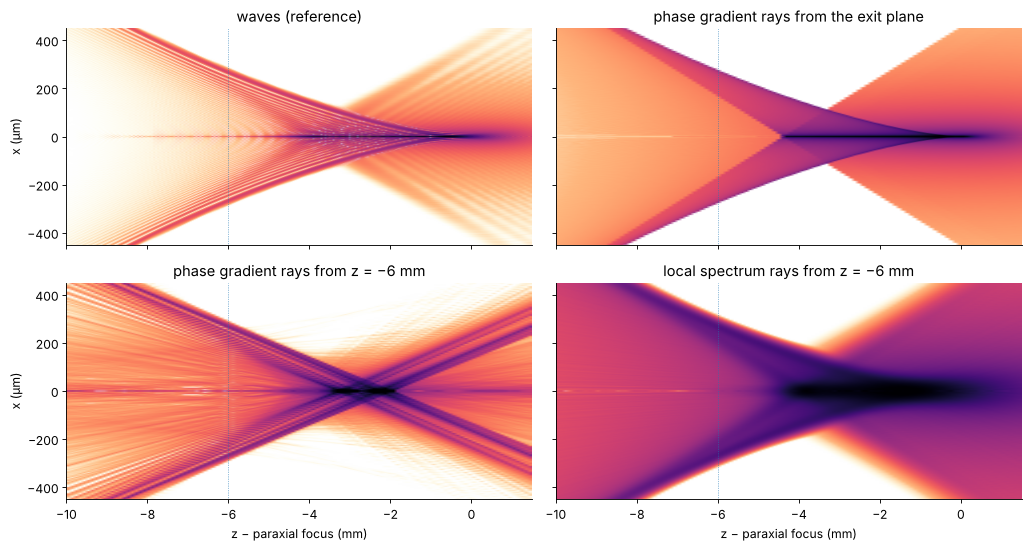

In [9]:
def rays_section(R, zs, x=x_f):
    """Ray density in the xz plane, using the rotational symmetry: the power of
    the rays in annuli of the plane, per area."""
    dx = x[1] - x[0]
    r_edges = np.arange(0, x[-1] + dx, dx)
    r_mid = 0.5*(r_edges[1:] + r_edges[:-1])
    area = np.pi*(r_edges[1:]**2 - r_edges[:-1]**2)
    rows = []
    for z in zs:
        Q, _ = straight_rays(R.points, R.directions, np.zeros(len(R.power)), foci[name] + z)
        E = np.histogram(np.hypot(Q[:, 0], Q[:, 1]), r_edges, weights=R.power)[0]/area
        rows.append(np.interp(np.abs(x), r_mid, E))
    return np.array(rows)


zs_r = zs[::2]
# the exit field as rays: the ray field of section 2 on 1024² samples (more
# rays), the sphere analytic
x_fine = grid1d(-10.2, 10.2, 1024)
P, D, S, launch = rays[name]
u_fine = rays_to_field(x_fine, x_fine, P, D, S, WL, launch=launch)
R_exit = field_to_rays(QuadraticPhaseField.from_field(u_fine, x_fine, x_fine, WL,
                                                      R=-fitted_radius(P, D)),
                       z=lenses[name].image_z)
# a 2D field inside the caustic, 6 mm before the paraxial focus
z_in = -6.0
x_in = grid1d(-0.5, 0.5, 512)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    u_in = propagate(exit_fields[name], foci[name] + z_in - lenses[name].image_z,
                     x_out=x_in, y_out=x_in).field()
R_grad = field_to_rays(u_in, x_in, x_in, WL, z=foci[name] + z_in, threshold=1e-4)
R_loc = local_spectrum_rays(u_in, x_in, x_in, WL, z=foci[name] + z_in, window=48, step=4,
                            threshold=1e-3, jitter=1)
print("rays: exit plane {}, phase gradient {}, local spectra {}".format(
    len(R_exit.power), len(R_grad.power), len(R_loc.power)))

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=True)
I_ref = np.abs(waves[name])**2
show(axes[0, 0], I_ref, zs)
axes[0, 0].set_title("waves (reference)")
for ax, R, title in ((axes[0, 1], R_exit, "phase gradient rays from the exit plane"),
                     (axes[1, 0], R_grad, "phase gradient rays from z = −6 mm"),
                     (axes[1, 1], R_loc, "local spectrum rays from z = −6 mm")):
    H = rays_section(R, zs_r)
    show(ax, H, zs_r, ref=np.percentile(H, 99.9))
    ax.set_title(title)
for ax in axes.ravel():
    ax.axvline(z_in, color="C0", lw=0.6, ls=":")
    ax.set_ylim(-450, 450), ax.set_xlim(zs[0], zs[-1])
for ax in axes[1]:
    ax.set_xlabel("z − paraxial focus (mm)")
for ax in axes[:, 0]:
    ax.set_ylabel("x (µm)")
plt.tight_layout()

### The Wigner function of the focus

The cleanest picture of the transition is phase space. The Wigner function
of a section u(x) of the field, W(x, k_x) = ∫ u(x + s/2) u*(x − s/2)
e^{−i k_x s} ds, shows where the light is and where it goes. For a field
that geometrical optics describes it sits on the curve of the rays,
k_x = n k₀ · (direction cosine) as a function of x: the **Lagrangian
manifold**. Here it is the S-shaped curve of the meridional ray fan,
traced, in the plane z = −6 mm. Where the curve folds back (vertical
tangent) the projection onto x, the intensity, has its caustics; between
the folds and the outer ends of the curve, two rays reach the same x. Between
the branches of the curve the Wigner function oscillates with positive and
negative values: the interference of the ray sheets that makes the fringes.
Its integral over k_x is the intensity of the wave. The faint structure off
the curve is again the edge diffracted wave.

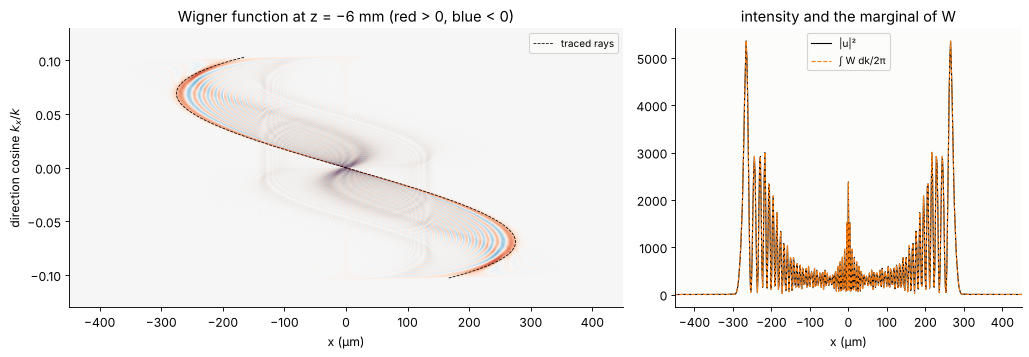

In [10]:
c = len(x_in)//2
k_w, W = wigner(u_in[c], x_in)
rho, r0, s, ze = fans[name]
dz = foci[name] + z_in - ze
r_ray = r0 + s*dz
k_ray = K*s/np.sqrt(1 + s**2)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
lim = np.max(np.abs(W))*0.3
axes[0].imshow(W, extent=[x_in[0]/um, x_in[-1]/um, k_w[0]/K, k_w[-1]/K], aspect="auto",
               cmap="RdBu_r", vmin=-lim, vmax=lim, interpolation="bilinear")
axes[0].plot(r_ray/um, k_ray/K, color="k", lw=0.7, ls="--", label="traced rays")
axes[0].set_ylim(-0.13, 0.13)
axes[0].set_xlim(-450, 450)
axes[0].set_xlabel("x (µm)"), axes[0].set_ylabel("direction cosine $k_x/k$")
axes[0].set_title("Wigner function at z = −6 mm (red > 0, blue < 0)")
axes[0].legend(loc="upper right", fontsize=9)
marginal = np.sum(W, 0)*(k_w[1] - k_w[0])/(2*np.pi)
axes[1].plot(x_in/um, np.abs(u_in[c])**2, "k", lw=1.0, label="|u|²")
axes[1].plot(x_in/um, marginal, "C1--", lw=1.0, label="∫ W dk/2π")
axes[1].set_xlabel("x (µm)"), axes[1].set_xlim(-450, 450)
axes[1].set_title("intensity and the marginal of W")
axes[1].legend(fontsize=9)
plt.tight_layout()

## 7. Which way round: the numbers

From the wave fields through focus: the highest peak intensity, relative
to the peak of the aberration free lens of the same aperture,
(πa²/(λf))² (the best Strehl ratio over focus), and the smallest radius
that holds 80 % of the power, each with the plane where it occurs. The
geometrical RMS spot radius at the paraxial focus for comparison.

In [11]:
def encircled_radius(x, I, frac=0.8):
    # rotationally symmetric: power within r from the profile I(|x|)
    r = x[x >= 0]
    Ir = I[x >= 0]
    E = np.cumsum(2*np.pi*r*Ir)
    return r[np.searchsorted(E/E[-1], frac)]


NA = A/np.hypot(A, 100.0)
I_airy = (np.pi*A**2/(WL*100.0))**2
print("{:18s} {:>12s} {:>10s} {:>14s} {:>10s} {:>12s}".format(
    "", "peak/Airy", "at z (mm)", "r80 min (µm)", "at z (mm)", "RMS spot (µm)"))
for n_ in lenses:
    I = np.abs(waves[n_])**2
    i_peak = np.argmax(I.max(1))
    r80 = np.array([encircled_radius(x_f, row) for row in I])
    i_r = np.argmin(r80)
    spot = lenses[n_].at_paraxial_focus().spot_diagram(0.0, 31)
    print("{:18s} {:12.3f} {:10.2f} {:14.1f} {:10.2f} {:12.1f}".format(
        n_, I.max()/I_airy, zs[i_peak], r80[i_r]/um, zs[i_r], spot.rms/um))
v = K*NA*x_f + 1e-12
print("aberration free: 80 % radius {:.1f} µm".format(encircled_radius(x_f, (2*j1(v)/v)**2)/um))

                      peak/Airy  at z (mm)   r80 min (µm)  at z (mm) RMS spot (µm)
curved side first         0.175      -0.30           21.0      -0.70         56.4
flat side first           0.042      -0.65           85.5      -2.65        226.9
aberration free: 80 % radius 3.0 µm


## Summary

- `raywave.rays_to_field()` converts a structured ray grid into a sampled
  field with phase k₀·OPL and the amplitude from the ray density, summing
  overlapping ray sheets with their Gouy phases. In front of a caustic it
  is the exact field; combined with `analytic_phase.QuadraticPhaseField`
  (sphere analytic, aberration sampled) 384² samples hand the traced
  lens over to a wave propagator.
- Through the focus of the plano-convex lens, the ray density shows the
  caustic (funnel, cusp, axial line), the wave intensity the fringes inside
  it, the shadow outside it and the finite peak on it. Ray field summation
  reproduces the fringes and fails only within a few µm of the caustics
  and in the shadow.
- `GaussianBeamlets` propagate rays with a width in closed form and agree
  with the wave field through the whole caustic, to a few per cent.
- `raywave.field_to_rays()` turns a single-sheet field back into rays
  (along the phase gradient, the energy flux); in a caustic, where sheets
  overlap, `local_spectrum_rays()` and the Wigner function (`wigner()`)
  assign several directions to one point. The Wigner function of the focus
  lies on the folded ray curve.
- Which way round: with the curved side towards the collimated beam the
  spherical aberration is four times smaller, the caustic four times
  shorter, and the peak intensity several times higher.

In [12]:
print("run time {:.0f} s".format(time.time() - t_start))

run time 145 s


## References

- M. Born and E. Wolf, *Principles of Optics*, 7th ed., Cambridge University Press (1999), ch. 3 (geometrical optics, eikonal and transport equations) and ch. 8.8 (the focus of an aberrated lens).
- Yu. A. Kravtsov and Yu. I. Orlov, *Caustics, Catastrophes and Wave Fields*, Springer (1993).
- V. P. Maslov and M. V. Fedoriuk, *Semi-Classical Approximation in Quantum Mechanics*, Reidel (1981).
- V. Červený, M. M. Popov and I. Pšenčík, "Computation of wave fields in inhomogeneous media - Gaussian beam approach", Geophys. J. R. Astr. Soc. 70, 109-128 (1982).
- J. A. Arnaud, "Representation of Gaussian beams by complex rays", Appl. Opt. 24, 538-543 (1985).
- A. W. Greynolds, "Propagation of generally astigmatic Gaussian beams along skew ray paths", Proc. SPIE 560, 33-50 (1985).
- M. J. Bastiaans, "Wigner distribution function and its application to first-order optics", J. Opt. Soc. Am. 69, 1710-1716 (1979).
- M. A. Alonso, "Wigner functions in optics: describing beams as ray bundles and pulses as particle ensembles", Adv. Opt. Photon. 3, 272-365 (2011).
- Z. Wang, O. Baladron-Zorita, C. Hellmann and F. Wyrowski, "Theory and algorithm of the homeomorphic Fourier transform for optical simulations", Opt. Express 28, 10552-10571 (2020).
- W. J. Smith, *Modern Optical Engineering*, 4th ed., McGraw-Hill (2008), ch. 3 (spherical aberration of a plano-convex lens and its bending).
- SCHOTT optical glass data sheet N-BK7 (n = 1.51509 at 632.8 nm).